Learned Policy:
 [['→' '→' '↓' '↓']
 ['↓' 'X' '↓' '↓']
 ['→' '→' '→' '↓']
 ['↑' '↑' 'X' 'G']]


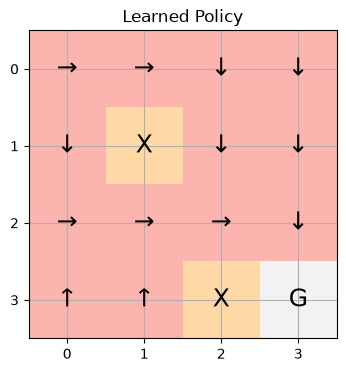

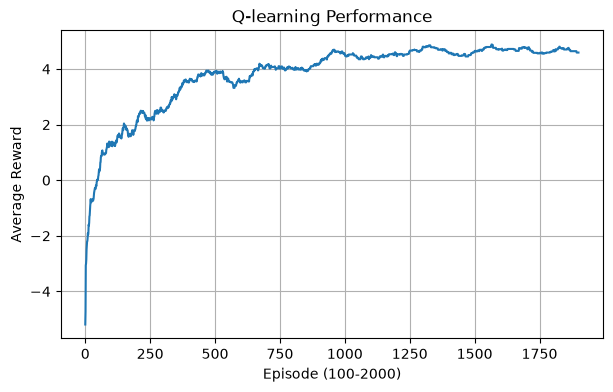

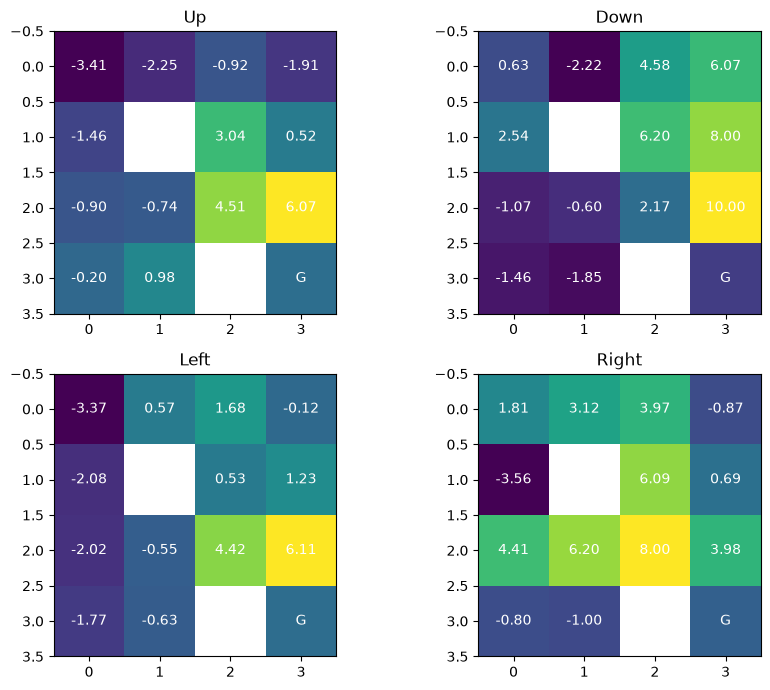


Q-values (Up, Down, Left, Right):
State (0, 0): [-3.41  0.63 -3.37  1.81]
State (0, 1): [-2.25 -2.22  0.57  3.12]
State (0, 2): [-0.92  4.58  1.68  3.97]
State (0, 3): [-1.91  6.07 -0.12 -0.87]
State (1, 0): [-1.46  2.54 -2.08 -3.56]
State (1, 1): Obstacle
State (1, 2): [3.04 6.2  0.53 6.09]
State (1, 3): [0.52 8.   1.23 0.69]
State (2, 0): [-0.9  -1.07 -2.02  4.41]
State (2, 1): [-0.74 -0.6  -0.55  6.2 ]
State (2, 2): [4.51 2.17 4.42 8.  ]
State (2, 3): [ 6.07 10.    6.11  3.98]
State (3, 0): [-0.2  -1.46 -1.77 -0.8 ]
State (3, 1): [ 0.98 -1.85 -0.63 -1.  ]
State (3, 2): Obstacle
State (3, 3): Goal


In [1]:
import numpy as np
import matplotlib.pyplot as plt

grid = np.array([[0, 0, 0, 0],
                 [0, 1, 0, 0],
                 [0, 0, 0, 0],
                 [0, 0, 1, 2]])

rows, cols = grid.shape
Q = np.zeros((rows * cols, 4))

moves = [(-1, 0), (1, 0), (0, -1), (0, 1)]
arrows = ['↑', '↓', '←', '→']
names = ['Up', 'Down', 'Left', 'Right']

alpha, gamma, epsilon = 0.1, 0.9, 0.3
episodes, rewards = 2000, []


def step(state, action):
    r, c = divmod(state, cols)
    dr, dc = moves[action]
    nr, nc = r + dr, c + dc

    if not (0 <= nr < rows and 0 <= nc < cols) or grid[nr, nc] == 1:
        return state, -5, False

    if grid[nr, nc] == 2:
        return nr * cols + nc, 10, True

    return nr * cols + nc, -1, False


for ep in range(episodes):
    state, total = 0, 0

    for _ in range(100):
        if np.random.random() < epsilon:
            action = np.random.randint(4)
        else:
            best = np.flatnonzero(Q[state] == Q[state].max())
            action = np.random.choice(best)

        nxt, reward, done = step(state, action)

        Q[state, action] += alpha * (
            reward + gamma * Q[nxt].max() * (not done) - Q[state, action]
        )

        state, total = nxt, total + reward

        if done:
            break

    rewards.append(total)
    epsilon = max(0.02, epsilon * 0.998)


policy = np.full((rows, cols), '', dtype=object)

for r in range(rows):
    for c in range(cols):
        if grid[r, c] == 1:
            policy[r, c] = 'X'
        elif grid[r, c] == 2:
            policy[r, c] = 'G'
        else:
            q = Q[r * cols + c]
            policy[r, c] = arrows[
                np.random.choice(np.flatnonzero(q == q.max()))
            ]

print("Learned Policy:\n", policy)

plt.figure(figsize=(5, 4))
plt.imshow(grid, cmap='Pastel1')

for r in range(rows):
    for c in range(cols):
        plt.text(c, r, policy[r, c],
                 ha='center', va='center', fontsize=18)

plt.title("Learned Policy")
plt.xticks(range(cols))
plt.yticks(range(rows))
plt.grid()
plt.show()


plt.figure(figsize=(7, 4))
plt.plot(np.convolve(rewards, np.ones(100)/100, mode='valid'))
plt.xlabel("Episode (100-2000)")
plt.ylabel("Average Reward")
plt.title("Q-learning Performance")
plt.grid()
plt.show()

fig, axes = plt.subplots(2, 2, figsize=(9, 7))

for a, ax in enumerate(axes.flat):
    values = Q[:, a].reshape(rows, cols)
    values[grid == 1] = np.nan

    ax.imshow(values, cmap='viridis')

    for r in range(rows):
        for c in range(cols):
            if grid[r, c] == 1:
                label = 'X'
            elif grid[r, c] == 2:
                label = 'G'
            else:
                label = f'{values[r,c]:.2f}'

            ax.text(c, r, label, ha='center', va='center', color='white')

    ax.set_title(names[a])

plt.tight_layout()
plt.show()


print("\nQ-values (Up, Down, Left, Right):")

for r in range(rows):
    for c in range(cols):
        state = r * cols + c
        result = "Obstacle" if grid[r,c] == 1 else "Goal" if grid[r,c] == 2 else np.round(Q[state], 2)
        print(f"State ({r}, {c}): {result}")